## WorldTrace NYC Mobility Patterns and Exceptions (Flag 1)

### Dataset Overview
A small subset of NYC trajectory-level records with movement mode, speed, distance, route indirectness, time, context, and coarse start and end regions.

The notebook exposes a primary table and a supporting table (`01_main_patterns_and_exceptions_points.csv`).

Goal: Examine the provided NYC trajectory records and explain the main regularities and deviations in the observed mobility behavior.

Role: NYC mobility insight analyst


Category: Main Patterns and Exceptions

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "01_main_patterns_and_exceptions.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "01_main_patterns_and_exceptions_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How do observed speed and route-indirectness patterns differ between the two movement modes?

#### Analysis action

Use the mode-specific distributions as the baseline when interpreting any unusually fast, slow, or indirect trajectory.

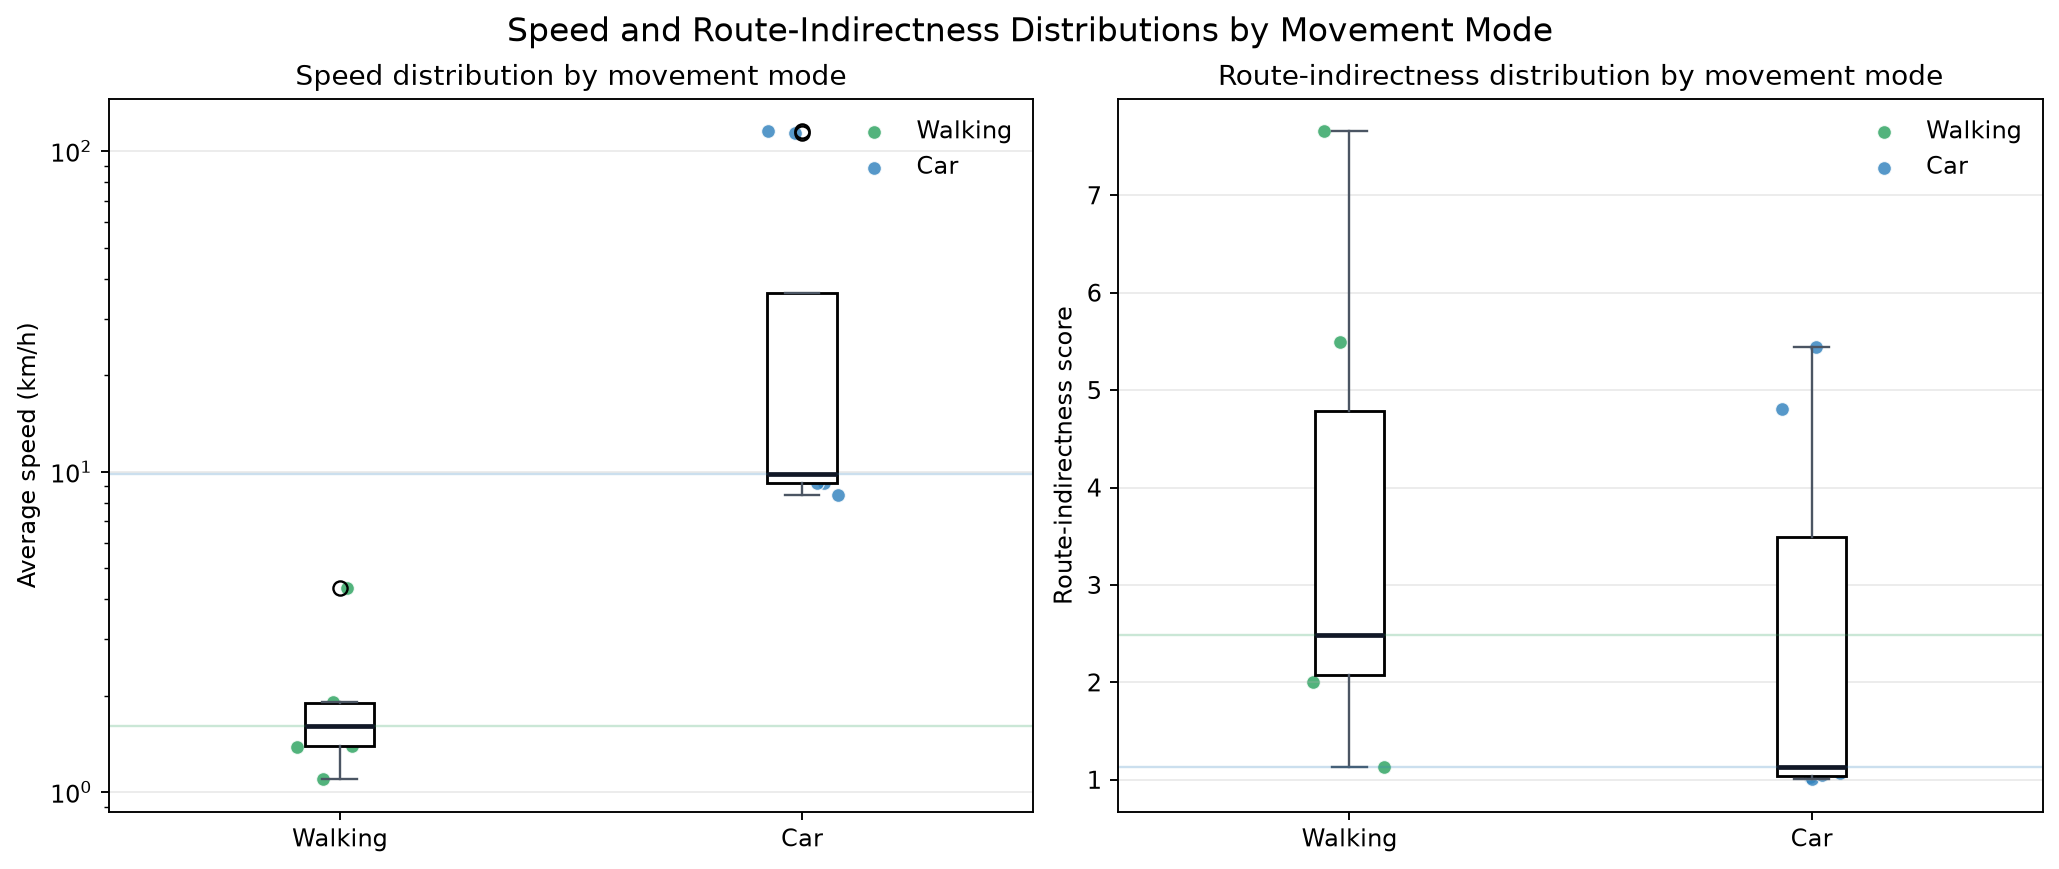

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

modes = ["walking", "car"]
colors = ["#2ca25f", "#3182bd"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
rng = np.random.default_rng(101)
for ax, column, ylabel, title in [
 (axes[0], "avg_speed_kmh", "Average speed (km/h)", "Speed distribution by movement mode"),
 (axes[1], "detour_score", "Route-indirectness score", "Route-indirectness distribution by movement mode"),
]:
 values = [df.loc[df["travel_mode"].eq(mode), column].dropna().to_numpy() for mode in modes]
 ax.boxplot(values, tick_labels=[m.title() for m in modes], patch_artist=True)
 for x, (mode, color, vals) in enumerate(zip(modes, colors, values), 1):
 jitter = rng.normal(x, 0.045, size=len(vals))
 ax.scatter(jitter, vals, s=34, alpha=0.82, color=color, edgecolor="white", linewidth=0.5, label=mode.title())
 ax.set_ylabel(ylabel)
 ax.set_title(title)
 ax.grid(axis="y", alpha=0.25)
 if column == "avg_speed_kmh":
 ax.set_yscale("log")
 ax.legend(frameon=False)
fig.suptitle("Speed and Route-Indirectness Distributions by Movement Mode")
plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/speed_and_route_indirectness_by_mode.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "descriptive",
  "insight": "Car trips have a higher median observed speed than walking trips, while walking trips have a higher median route-indirectness score in the selected records.",
  "insight_value": {
    "median_speed_kmh": {
      "walking": 1.61,
      "car": 9.87
    },
    "median_detour_score": {
      "walking": 2.49,
      "car": 1.13
    }
  },
  "plot": {
    "plot_type": "two_panel_distribution",
    "title": "Speed and Route-Indirectness Distributions by Movement Mode",
    "file": "visualizations/speed_and_route_indirectness_by_mode.png",
    "x_axis": {
      "name": "Movement mode",
      "description": "Walking and car trajectories in the provided records."
    },
    "y_axis": {
      "name": "Metric value",
      "description": "The left panel shows average speed; the right panel shows route-indirectness score."
    },
    "description": "Boxplots and jittered observations show both the speed and route-indirectness distributions for walking and car trajectories."
  },
  "question": "How do observed speed and route-indirectness patterns differ between the two movement modes?",
  "actionable_insight": "Use the mode-specific distributions as the baseline when interpreting any unusually fast, slow, or indirect trajectory.",
  "code": "import matplotlib.pyplot as plt\nimport numpy as np\n\nmodes = [\"walking\", \"car\"]\ncolors = [\"#2ca25f\", \"#3182bd\"]\nfig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)\nrng = np.random.default_rng(101)\nfor ax, column, ylabel, title in [\n (axes[0], \"avg_speed_kmh\", \"Average speed (km/h)\", \"Speed distribution by movement mode\"),\n (axes[1], \"detour_score\", \"Route-indirectness score\", \"Route-indirectness distribution by movement mode\"),\n]:\n values = [df.loc[df[\"travel_mode\"].eq(mode), column].dropna().to_numpy() for mode in modes]\n ax.boxplot(values, tick_labels=[m.title() for m in modes], patch_artist=True)\n for x, (mode, color, vals) in enumerate(zip(modes, colors, values), 1):\n jitter = rng.normal(x, 0.045, size=len(vals))\n ax.scatter(jitter, vals, s=34, alpha=0.82, color=color, edgecolor=\"white\", linewidth=0.5, label=mode.title())\n ax.set_ylabel(ylabel)\n ax.set_title(title)\n ax.grid(axis=\"y\", alpha=0.25)\n if column == \"avg_speed_kmh\":\n ax.set_yscale(\"log\")\n ax.legend(frameon=False)\nfig.suptitle(\"Speed and Route-Indirectness Distributions by Movement Mode\")\nplt.show()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### **Question 2**: Which trajectories depart from the ordinary joint pattern of speed, distance, and route indirectness?

#### Analysis action

Treat deviations in speed and distance as candidate anomalies and inspect their trajectory paths.

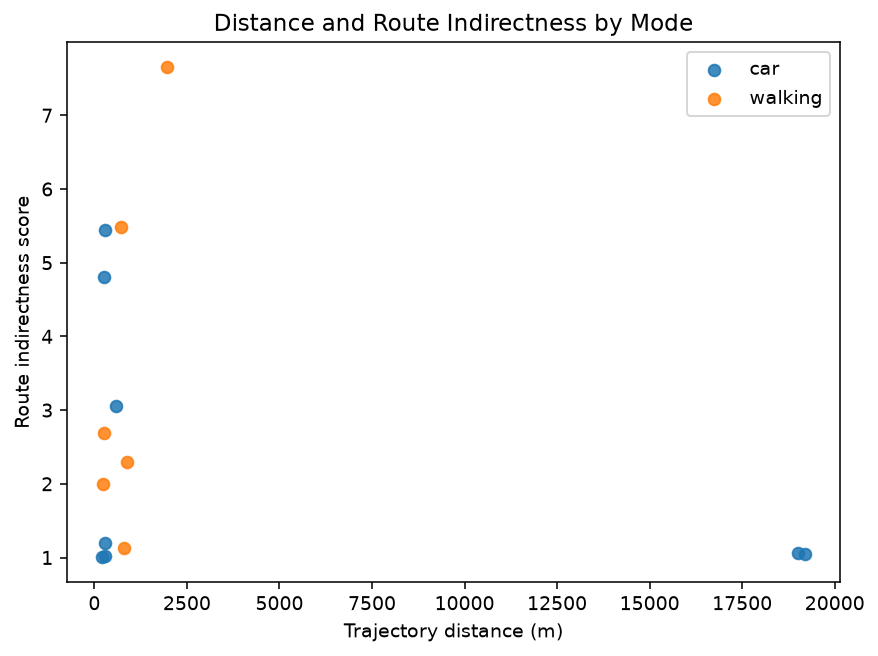

In [ ]:
import matplotlib.pyplot as plt

# Inspect distance and route indirectness jointly for each mode.
for mode, group in df.groupby("travel_mode"):
 plt.scatter(group["distance_meters"], group["detour_score"], label=mode, alpha=0.85)
plt.xlabel("Trajectory distance (m)")
plt.ylabel("Route indirectness score")
plt.title("Distance and Route Indirectness by Mode")
plt.legend()
plt.tight_layout()
plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q2_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "diagnostic",
  "insight": "A small number of trajectories deviate from the usual speed and distance patterns of the collection.",
  "insight_value": {
    "dimensions": [
      "avg_speed_kmh",
      "distance_meters",
      "detour_score"
    ]
  },
  "plot": {
    "plot_type": "scatter",
    "title": "Distance and Route Indirectness by Mode",
    "x_axis": {
      "name": "Trajectory distance (m)",
      "description": "The observed trajectory distance."
    },
    "y_axis": {
      "name": "Route indirectness score",
      "description": "The observed route-indirectness summary."
    },
    "description": "The scatter plot shows whether unusual indirectness is concentrated among short, long, fast, or slow records.",
    "file": "notebook_plots/q2_1.png"
  },
  "question": "Which trajectories depart from the ordinary joint pattern of speed, distance, and route indirectness?",
  "actionable_insight": "Treat deviations in speed and distance as candidate anomalies and inspect their trajectory paths.",
  "code": "import matplotlib.pyplot as plt\n\n# Inspect distance and route indirectness jointly for each mode.\nfor mode, group in df.groupby(\"travel_mode\"):\n plt.scatter(group[\"distance_meters\"], group[\"detour_score\"], label=mode, alpha=0.85)\nplt.xlabel(\"Trajectory distance (m)\")\nplt.ylabel(\"Route indirectness score\")\nplt.title(\"Distance and Route Indirectness by Mode\")\nplt.legend()\nplt.tight_layout()\nplt.show()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### **Question 3**: Do trajectories that deviate from the normal speed and distance ranges contain isolated GPS points outside their main paths?

#### Analysis action

Check whether isolated points outside a main trajectory path may account for an apparent speed or distance deviation.

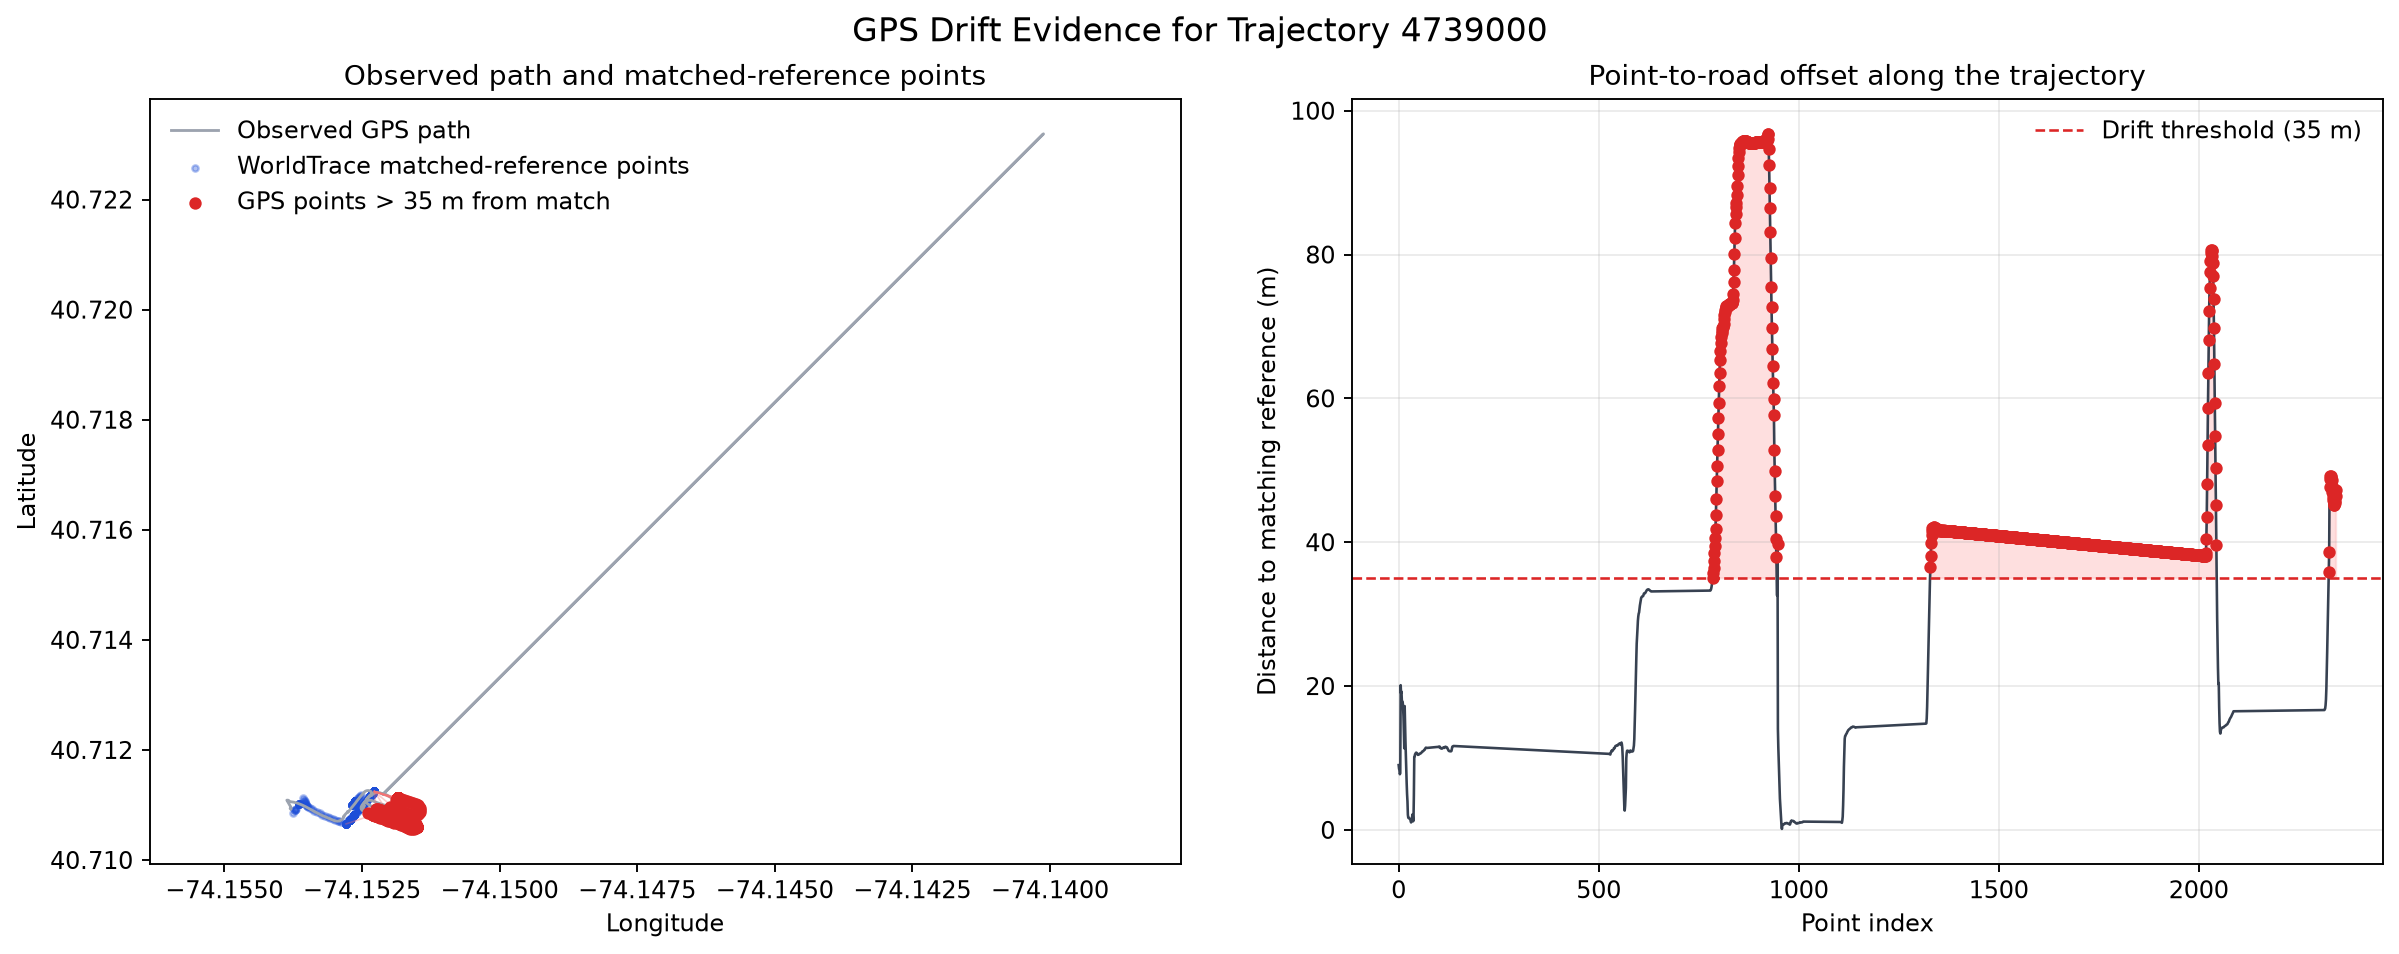

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

points = pd.read_csv(user_dataset_path)
target = points[points["trajectory_id"].eq(4739000)].sort_values("point_index").copy()
threshold = 35.0
drift = target[target["matched_distance"] > threshold]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), constrained_layout=True)
axes[0].plot(target["longitude"], target["latitude"], color="#9ca3af", label="Observed GPS path")
axes[0].scatter(target["matched_longitude"], target["matched_latitude"], color="#1d4ed8", s=7, alpha=0.35, label="WorldTrace matched-reference points")
axes[0].scatter(drift["longitude"], drift["latitude"], color="#dc2626", s=18, label=f"GPS points > {threshold:.0f} m from match")
axes[0].set_title("Observed path and matched-reference points")
axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude"); axes[0].axis("equal"); axes[0].legend(frameon=False)
axes[1].plot(target["point_index"], target["matched_distance"], color="#374151")
axes[1].scatter(drift["point_index"], drift["matched_distance"], color="#dc2626", s=18)
axes[1].axhline(threshold, color="#dc2626", linestyle="--", label=f"Drift threshold ({threshold:.0f} m)")
axes[1].set_title("Distance to matching reference along the trajectory")
axes[1].set_xlabel("Point index"); axes[1].set_ylabel("Distance to matching reference (m)"); axes[1].grid(alpha=0.25); axes[1].legend(frameon=False)
fig.suptitle("GPS Drift Evidence for Trajectory 4739000")
plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/gps_drift_profile.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "diagnostic",
  "insight": "Some trajectories that deviate from the normal speed and distance ranges contain isolated GPS points that drift outside their main trajectory paths, possibly because of positioning errors.",
  "insight_value": {
    "required_evidence": [
      "trajectory_id",
      "point_index",
      "latitude",
      "longitude",
      "matched_latitude",
      "matched_longitude"
    ]
  },
  "plot": {
    "plot_type": "trajectory_map_and_offset_profile",
    "title": "GPS Drift Evidence for Trajectory 4739000",
    "file": "visualizations/gps_drift_profile.png",
    "x_axis": {
      "name": "Point index / longitude",
      "description": "The right panel uses point index; the left panel shows the observed trajectory and the per-point matching references."
    },
    "y_axis": {
      "name": "Distance to matching reference (m) / latitude",
      "description": "The two panels identify displaced GPS observations and their distance from the WorldTrace matching reference."
    },
    "description": "The left panel compares the observed GPS path with per-point WorldTrace matching-reference coordinates. The blue markers are not a road-network basemap or a connected road geometry; the right panel shows point-to-reference offsets over the trajectory."
  },
  "question": "Do trajectories that deviate from the normal speed and distance ranges contain isolated GPS points outside their main paths?",
  "actionable_insight": "Check whether isolated points outside a main trajectory path may account for an apparent speed or distance deviation.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\n\npoints = pd.read_csv(user_dataset_path)\ntarget = points[points[\"trajectory_id\"].eq(4739000)].sort_values(\"point_index\").copy()\nthreshold = 35.0\ndrift = target[target[\"matched_distance\"] > threshold]\nfig, axes = plt.subplots(1, 2, figsize=(14, 5.5), constrained_layout=True)\naxes[0].plot(target[\"longitude\"], target[\"latitude\"], color=\"#9ca3af\", label=\"Observed GPS path\")\naxes[0].scatter(target[\"matched_longitude\"], target[\"matched_latitude\"], color=\"#1d4ed8\", s=7, alpha=0.35, label=\"WorldTrace matched-reference points\")\naxes[0].scatter(drift[\"longitude\"], drift[\"latitude\"], color=\"#dc2626\", s=18, label=f\"GPS points > {threshold:.0f} m from match\")\naxes[0].set_title(\"Observed path and matched-reference points\")\naxes[0].set_xlabel(\"Longitude\"); axes[0].set_ylabel(\"Latitude\"); axes[0].axis(\"equal\"); axes[0].legend(frameon=False)\naxes[1].plot(target[\"point_index\"], target[\"matched_distance\"], color=\"#374151\")\naxes[1].scatter(drift[\"point_index\"], drift[\"matched_distance\"], color=\"#dc2626\", s=18)\naxes[1].axhline(threshold, color=\"#dc2626\", linestyle=\"--\", label=f\"Drift threshold ({threshold:.0f} m)\")\naxes[1].set_title(\"Distance to matching reference along the trajectory\")\naxes[1].set_xlabel(\"Point index\"); axes[1].set_ylabel(\"Distance to matching reference (m)\"); axes[1].grid(alpha=0.25); axes[1].legend(frameon=False)\nfig.suptitle(\"GPS Drift Evidence for Trajectory 4739000\")\nplt.show()",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_timestamp",
    "matched_road_position",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 1)

The records show a clear mode-associated difference in both speed and route indirectness, together with a small number of trajectories that deviate from the usual speed and distance patterns. The revised drift view compares observed GPS positions with WorldTrace per-point matching references and shows where the point-to-reference offsets become unusually large; the reference markers are not a connected road map.